# **Final Self-RAG: Adaptive Retrieval, Verification and Query Rewriting**

![Self-RAG Workflow Infographic for Company QA.png](<attachment:Self-RAG Workflow Infographic for Company QA.png>)

<div align="center">
<img src="assets/final-self-rag-agent-graph.png" alt="Final Self-RAG Agent Graph" width="700">
</div>
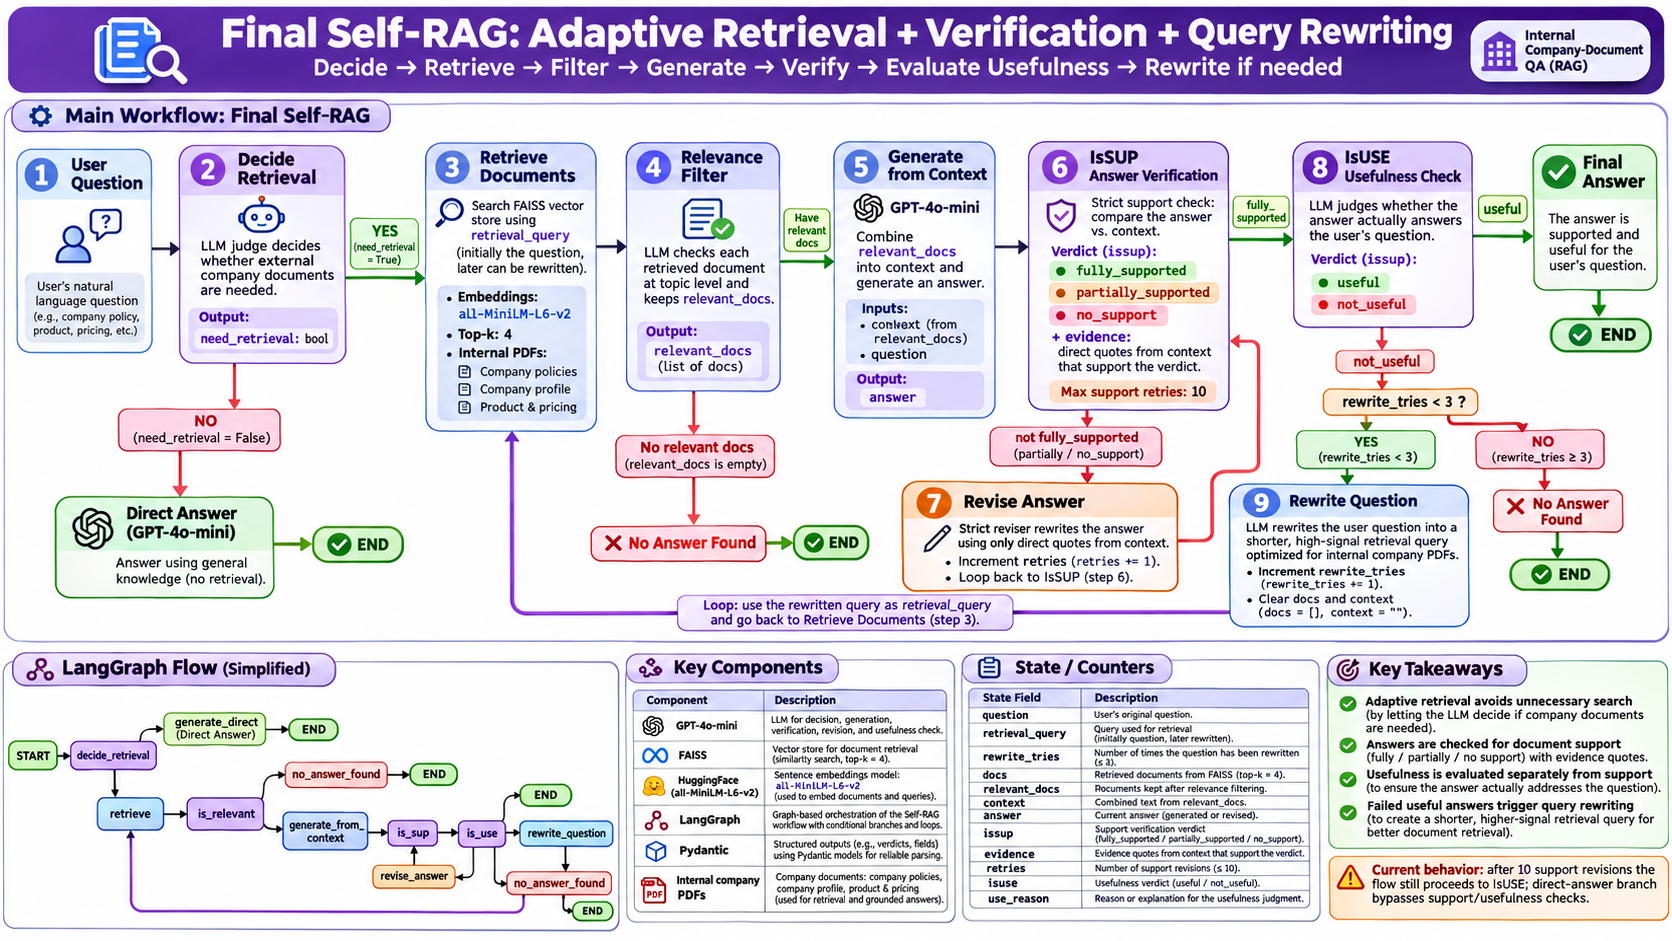

This notebook builds a **Self-RAG-inspired question-answering workflow** using LangGraph, FAISS, Hugging Face embeddings and GPT-4o-mini.

1. **Decide retrieval:** Answer general questions directly or retrieve internal company documents.
2. **Filter evidence:** Retrieve top-4 FAISS chunks, then keep documents judged topically relevant.
3. **Generate:** Build a response using the accepted context.
4. **IsSUP:** Verify evidence support; revise unsupported responses and recheck (up to 10 times).
5. **IsUSE:** Check whether the response actually addresses the question.
6. **Rewrite and retry:** If not useful, rewrite the vector-search query and re-retrieve (up to 3 rewrites).


In [ ]:
import os
from typing import List, TypedDict, Literal
from pydantic import BaseModel, Field

from langchain_community.document_loaders import PyPDFLoader
from langchain_community.vectorstores import FAISS
from langchain_huggingface import HuggingFaceEmbeddings
from langchain_openai import OpenAIEmbeddings, ChatOpenAI
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_core.documents import Document
from langchain_core.prompts import ChatPromptTemplate

from langgraph.graph import StateGraph, START, END
from dotenv import load_dotenv

# Load environment variables from .env before reading API configuration.
load_dotenv()

api_key = os.getenv("OPENAI_API_KEY")
base_url = os.getenv("BASE_URL")

In [2]:
# Set False to rebuild the FAISS index from the source PDFs; True loads the saved index.
# True: reuse an existing trusted FAISS index; False: rebuild from PDFs.
faiss_saved = True

# Build and save the index when no reusable local index is selected.
# Index construction must use the same embedding model as subsequent retrieval.
if faiss_saved==False:
    # Load the company policy, profile, and pricing PDFs as LangChain Documents.
    docs = (
        PyPDFLoader("./documents/DSwithBappy_Company_Policies.pdf").load()
        + PyPDFLoader("./documents/DSwithBappy_Company_Profile.pdf").load()
        + PyPDFLoader("./documents/DSwithBappy_Product_and_Pricing.pdf").load()

    )
    # Split long documents into overlapping passages for retrieval.
    chunks = RecursiveCharacterTextSplitter(
    chunk_size=600, chunk_overlap=150
    ).split_documents(docs)
    # Create the sentence-transformer encoder used for document and query vectors.
    hf_embeddings = HuggingFaceEmbeddings(model_name='sentence-transformers/all-MiniLM-L6-v2')
    # Embed the chunks and build a FAISS similarity-search index.
    vector_store = FAISS.from_documents(chunks, hf_embeddings)
    # Configure retrieval to return the four nearest chunks per query.
    retriever = vector_store.as_retriever(search_type="similarity", search_kwargs={"k": 4})
    
else:
    # Create the sentence-transformer encoder used for document and query vectors.
    hf_embeddings = HuggingFaceEmbeddings(model_name='sentence-transformers/all-MiniLM-L6-v2')
    # Restore the saved FAISS index; only load an index you trust.
    # WARNING: FAISS deserialization uses pickle. Only load a trusted local index.
    vector_store = FAISS.load_local("faiss_index", hf_embeddings, allow_dangerous_deserialization=True)
    # Configure retrieval to return the four nearest chunks per query.
    retriever = vector_store.as_retriever(search_type="similarity", search_kwargs={"k": 4})


In [21]:
retriever.invoke("Bappy founder name")

[Document(id='093b77cb-43e7-4e3f-8b5f-26c3d24117fe', metadata={'producer': 'ReportLab PDF Library - (opensource)', 'creator': '(unspecified)', 'creationdate': '2026-08-26T04:40:11+00:00', 'author': '(anonymous)', 'keywords': '', 'moddate': '2026-08-26T04:40:11+00:00', 'subject': '(unspecified)', 'title': '(anonymous)', 'trapped': '/False', 'source': './documents/DSwithBappy_Company_Profile.pdf', 'total_pages': 2, 'page': 1, 'page_label': '2'}, page_content='Founder\nBappy founded DSwithBappy with the goal of making modern AI engineering easier to\nunderstand through practical, step-by-step learning.\nThrough technical tutorials, courses, end-to-end projects, and community content, DSwithBappy\nfocuses on helping learners turn AI concepts into working applications.\nPlatform & Learning Team\nDSwithBappy brings together content creation, AI engineering, course development, project\nbuilding, and learner support to create a practical learning experience.\n●\nAI Engineering & Project Devel

In [3]:
# Temperature 0 makes judgments more reproducible, but does not guarantee identical outputs.
llm = ChatOpenAI(model="gpt-4o-mini", temperature=0, api_key=api_key, base_url=base_url)

In [4]:
# -----------------------------
# Graph State
# -----------------------------
# Shared LangGraph state. Each node returns only fields that it updates.
class State(TypedDict):
    question: str

    # ✅ NEW: what we actually send to vector retriever
    # Retrieval text can differ from the original question after query rewriting.
    retrieval_query: str
    rewrite_tries: int
    
    need_retrieval: bool
    docs: List[Document]
    relevant_docs: List[Document]
    context: str
    answer: str

    # Post-generation verification
    issup: Literal["fully_supported", "partially_supported", "no_support"]
    evidence: List[str]

    # Count support-revision attempts separately from retrieval-query rewrites.
    retries: int

    isuse: Literal["useful", "not_useful"]
    use_reason: str

In [5]:
# -----------------------------
# 1) Decide retrieval
# -----------------------------
# Structured schema prevents ambiguous free-text yes/no parsing.
class RetrieveDecision(BaseModel):
    should_retrieve: bool = Field(
        ...,
        description="True if external documents are needed to answer reliably, else False."
    )

decide_retrieval_prompt = ChatPromptTemplate.from_messages(
    [
        (
            "system",
            "You decide whether retrieval is needed.\n"
            "Return JSON with key: should_retrieve (boolean).\n\n"
            "Guidelines:\n"
            "- should_retrieve=True if answering requires specific facts from company documents.\n"
            "- should_retrieve=False for general explanations/definitions.\n"
            "- If unsure, choose True."
        ),
        ("human", "Question: {question}"),
    ]
)

should_retrieve_llm = llm.with_structured_output(RetrieveDecision)

def decide_retrieval(state: State):
    decision: RetrieveDecision = should_retrieve_llm.invoke(
        decide_retrieval_prompt.format_messages(question=state["question"])
    )
    return {"need_retrieval": decision.should_retrieve}

# Conditional edge: direct-answer questions bypass the entire retrieval/verification path.
def route_after_decide(state: State) -> Literal["generate_direct", "retrieve"]:
    return "retrieve" if state["need_retrieval"] else "generate_direct"


In [6]:
# -----------------------------
# 2) Direct answer (no retrieval)
# -----------------------------
direct_generation_prompt = ChatPromptTemplate.from_messages(
    [
        (
            "system",
            "Answer using only your general knowledge.\n"
            "If it requires specific company info, say:\n"
            "'I don't know based on my general knowledge.'"
        ),
        ("human", "{question}"),
    ]
)

# This path uses model knowledge and is NOT checked by IsSUP or IsUSE.
def generate_direct(state: State):
    out = llm.invoke(direct_generation_prompt.format_messages(question=state["question"]))
    return {"answer": out.content}


In [7]:
# -----------------------------
# 3) Retrieve
# -----------------------------
def retrieve(state: State):
# Prefer the rewritten query when available; otherwise use the original question.
    q = state.get("retrieval_query") or state["question"]
    return {"docs": retriever.invoke(q)}



In [8]:
# -----------------------------
# 4) Relevance filter (strict)
# -----------------------------
class RelevanceDecision(BaseModel):
    is_relevant: bool = Field(
        ...,
        description="True ONLY if the document contains info that can directly answer the question."
    )

is_relevant_prompt = ChatPromptTemplate.from_messages(
    [
        (
            "system",
            "You are judging document relevance at a TOPIC level.\n"
            "Return JSON matching the schema.\n\n"
            "A document is relevant if it discusses the same entity or topic area as the question.\n"
            "It does NOT need to contain the exact answer.\n\n"
            "Examples:\n"
            "- HR policies are relevant to questions about notice period, probation, termination, benefits.\n"
            "- Pricing documents are relevant to questions about refunds, trials, billing terms.\n"
            "- Company profile is relevant to questions about leadership, culture, size, or strategy.\n\n"
            "Do NOT decide whether the document fully answers the question.\n"
            "That will be checked later by IsSUP.\n"
            "When unsure, return is_relevant=true."
        ),
        ("human", "Question:\n{question}\n\nDocument:\n{document}"),
    ]
)


# Ask for a typed Boolean verdict for each candidate document.
relevance_llm = llm.with_structured_output(RelevanceDecision)

def is_relevant(state: State):
    relevant_docs: List[Document] = []
# One sequential LLM call per chunk: simple but potentially high latency/cost.
    for doc in state.get("docs", []):
        decision: RelevanceDecision = relevance_llm.invoke(
            is_relevant_prompt.format_messages(
                question=state["question"],
                document=doc.page_content,
            )
        )
        if decision.is_relevant:
            relevant_docs.append(doc)
    return {"relevant_docs": relevant_docs}

# If no chunks pass the filter, this notebook terminates instead of rewriting.
def route_after_relevance(state: State) -> Literal["generate_from_context", "no_answer_found"]:
    if state.get("relevant_docs") and len(state["relevant_docs"]) > 0:
        return "generate_from_context"
    return "no_answer_found"


In [9]:
# -----------------------------
# 5) Generate from context
# -----------------------------
rag_generation_prompt = ChatPromptTemplate.from_messages(
    [
        (
            "system",
            "You are a business rag chatbot.\n\n"
            "You will receive a CONTEXT block from internal company documents.\n"
            "Task:\n"
            "Answer the question based on the context"
            "Dont mention that you are getting a context in your answer"
        ),
        ("human", "Question:\n{question}\n\nContext:\n{context}"),
    ]
)

def generate_from_context(state: State):
# Join accepted chunks into one evidence block, separated for readability.
    context = "\n\n---\n\n".join([d.page_content for d in state.get("relevant_docs", [])]).strip()
# Guard against empty evidence before calling the answer generator.
    if not context:
        return {"answer": "No answer found.", "context": ""}
    out = llm.invoke(
        rag_generation_prompt.format_messages(question=state["question"], context=context)
    )
    return {"answer": out.content, "context": context}



In [10]:
def no_answer_found(state: State):
    return {"answer": "No answer found.", "context": ""}

In [11]:
# -----------------------------
# 6) IsSUP verify + revise loop
# -----------------------------
# IsSUP evaluates answer support and returns short verbatim evidence excerpts.
class IsSUPDecision(BaseModel):
    issup: Literal["fully_supported", "partially_supported", "no_support"]
    evidence: List[str] = Field(default_factory=list)

issup_prompt = ChatPromptTemplate.from_messages(
    [
        (
            "system",
            "You are verifying whether the ANSWER is supported by the CONTEXT.\n"
            "Return JSON with keys: issup, evidence.\n"
            "issup must be one of: fully_supported, partially_supported, no_support.\n\n"
            "How to decide issup:\n"
            "- fully_supported:\n"
            "  Every meaningful claim is explicitly supported by CONTEXT, and the ANSWER does NOT introduce\n"
            "  any qualitative/interpretive words that are not present in CONTEXT.\n"
            "  (Examples of disallowed words unless present in CONTEXT: culture, generous, robust, designed to,\n"
            "  supports professional development, best-in-class, employee-first, etc.)\n\n"
            "- partially_supported:\n"
            "  The core facts are supported, BUT the ANSWER includes ANY abstraction, interpretation, or qualitative\n"
            "  phrasing not explicitly stated in CONTEXT (e.g., calling policies 'culture', saying leave is 'generous',\n"
            "  or inferring outcomes like 'supports professional development').\n\n"
            "- no_support:\n"
            "  The key claims are not supported by CONTEXT.\n\n"
            "Rules:\n"
            "- Be strict: if you see ANY unsupported qualitative/interpretive phrasing, choose partially_supported.\n"
            "- If the answer is mostly unrelated to the question or unsupported, choose no_support.\n"
            "- Evidence: include up to 3 short direct quotes from CONTEXT that support the supported parts.\n"
            "- Do not use outside knowledge."
        ),
        (
            "human",
            "Question:\n{question}\n\n"
            "Answer:\n{answer}\n\n"
            "Context:\n{context}\n"
        ),
    ]
)



issup_llm = llm.with_structured_output(IsSUPDecision)

def is_sup(state: State):
    decision: IsSUPDecision = issup_llm.invoke(
        issup_prompt.format_messages(
            question=state["question"],
            answer=state.get("answer", ""),
            context=state.get("context", ""),
        )
    )
    return {"issup": decision.issup, "evidence": decision.evidence}


# Bound the answer-revision loop to prevent unending LLM calls.
MAX_RETRIES = 10

def route_after_issup(state: State) -> Literal["accept_answer", "revise_answer"]:
    # fully supported -> move forward to IsUSE (via "accept_answer" label)
    if state.get("issup") == "fully_supported":
        return "accept_answer"

# CAUTION: after the cap, routing proceeds to IsUSE even if IsSUP is not fully_supported.
    if state.get("retries", 0) >= MAX_RETRIES:
        return "accept_answer"  # will go to is_use, then likely not_useful -> no_answer_found

    return "revise_answer"


In [12]:
def accept_answer(state: State):
# This node is defined but not registered in the current graph.
    return {}  # keep answer as-is


In [13]:
revise_prompt = ChatPromptTemplate.from_messages(
    [
        (
            "system",
            "You are a STRICT reviser.\n\n"
            "You must output based on the following format:\n\n"
            "FORMAT (quote-only answer):\n"
            "- <direct quote from the CONTEXT>\n"
            "- <direct quote from the CONTEXT>\n\n"
            "Rules:\n"
            "- Use ONLY the CONTEXT.\n"
            "- Do NOT add any new words besides bullet dashes and the quotes themselves.\n"
            "- Do NOT explain anything.\n"
            "- Do NOT say 'context', 'not mentioned', 'does not mention', 'not provided', etc.\n"
        ),
        (
            "human",
            "Question:\n{question}\n\n"
            "Current Answer:\n{answer}\n\n"
            "CONTEXT:\n{context}"
        ),
    ]
)



# Rewrite strictly from retrieved evidence, then let IsSUP grade the revision again.
def revise_answer(state: State):
    out = llm.invoke(
        revise_prompt.format_messages(
            question=state["question"],
            answer=state.get("answer", ""),
            context=state.get("context", ""),
        )
    )
    return {
        "answer": out.content,
# Increment only the support-revision counter (not the query-rewrite counter).
        "retries": state.get("retries", 0) + 1,  # ✅ increment
    }



In [14]:
# IsUSE checks question-answer fit, not factual grounding (handled by IsSUP).
class IsUSEDecision(BaseModel):
    isuse: Literal["useful", "not_useful"]
    reason: str = Field(..., description="Short reason in 1 line.")

isuse_prompt = ChatPromptTemplate.from_messages(
    [
        (
            "system",
            "You are judging USEFULNESS of the ANSWER for the QUESTION.\n\n"
            "Goal:\n"
            "- Decide if the answer actually addresses what the user asked.\n\n"
            "Return JSON with keys: isuse, reason.\n"
            "isuse must be one of: useful, not_useful.\n\n"
            "Rules:\n"
            "- useful: The answer directly answers the question or provides the requested specific info.\n"
            "- not_useful: The answer is generic, off-topic, or only gives related background without answering.\n"
            "- Do NOT use outside knowledge.\n"
            "- Do NOT re-check grounding (IsSUP already did that). Only check: 'Did we answer the question?'\n"
            "- Keep reason to 1 short line."
        ),
        (
            "human",
            "Question:\n{question}\n\nAnswer:\n{answer}"
        ),
    ]
)

isuse_llm = llm.with_structured_output(IsUSEDecision)

def is_use(state: State):
    decision: IsUSEDecision = isuse_llm.invoke(
        isuse_prompt.format_messages(
            question=state["question"],
            answer=state.get("answer", ""),
        )
    )
    return {"isuse": decision.isuse, "use_reason": decision.reason}

# A separate limit for rephrasing and rerunning the vector search.
MAX_REWRITE_TRIES = 3  # tune (2–4 is usually fine)

# Useful answers finish; unhelpful ones may retry retrieval with a rewritten query.
def route_after_isuse(state: State) -> Literal["END", "rewrite_question", "no_answer_found"]:
    if state.get("isuse") == "useful":
        return "END"

    if state.get("rewrite_tries", 0) >= MAX_REWRITE_TRIES:
        return "no_answer_found"

    return "rewrite_question"




In [15]:
# LLM returns a short search query; it must not answer the question.
class RewriteDecision(BaseModel):
    retrieval_query: str = Field(
        ...,
        description="Rewritten query optimized for vector retrieval against internal company PDFs."
    )

rewrite_for_retrieval_prompt = ChatPromptTemplate.from_messages(
    [
        (
            "system",
            "Rewrite the user's QUESTION into a query optimized for vector retrieval over INTERNAL company PDFs.\n\n"
            "Rules:\n"
            "- Keep it short (6–16 words).\n"
            "- Preserve key entities (e.g., NexaAI, plan names).\n"
            "- Add 2–5 high-signal keywords that likely appear in policy/pricing docs.\n"
            "- Remove filler words.\n"
            "- Do NOT answer the question.\n"
            "- Output JSON with key: retrieval_query\n\n"
            "Examples:\n"
            "Q: 'Do NexaAI plans include a free trial?'\n"
            "-> {{'retrieval_query': 'NexaAI free trial duration trial period plans'}}\n\n"
            "Q: 'What is NexaAI refund policy?'\n"
            "-> {{'retrieval_query': 'NexaAI refund policy cancellation refund timeline charges'}}"
        ),
        (
            "human",
            "QUESTION:\n{question}\n\n"
            "Previous retrieval query:\n{retrieval_query}\n\n"
            "Answer (if any):\n{answer}"
        ),
    ]
)



rewrite_llm = llm.with_structured_output(RewriteDecision)

# Query rewriting happens only after an IsUSE failure, not after an empty relevance filter.
def rewrite_question(state: State):
    decision: RewriteDecision = rewrite_llm.invoke(
        rewrite_for_retrieval_prompt.format_messages(
            question=state["question"],
            retrieval_query=state.get("retrieval_query", ""),
            answer=state.get("answer", ""),
        )
    )

    return {
        "retrieval_query": decision.retrieval_query,
# Track this loop independently from IsSUP revisions.
        "rewrite_tries": state.get("rewrite_tries", 0) + 1,
        # ✅ optional: reset these so next pass is clean
        "docs": [],
        "relevant_docs": [],
        "context": "",
    }


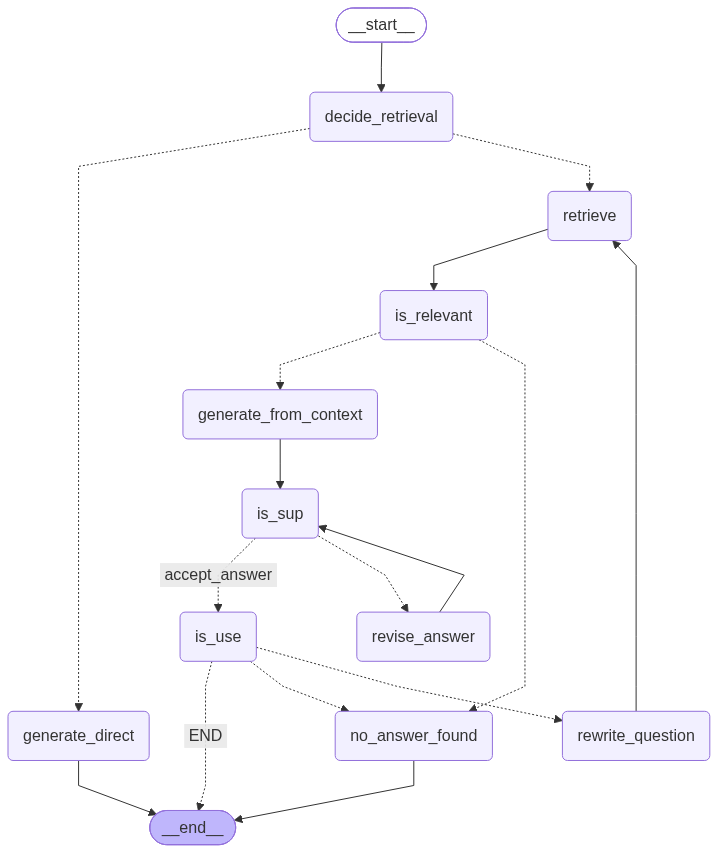

In [16]:
# -----------------------------
# Build graph (UPDATED: IsUSE -> if not useful -> rewrite -> retrieve; else END)
# -----------------------------
# Wire nodes and conditional edges into the executable graph.
g = StateGraph(State)

# --------------------
# Nodes
# --------------------
g.add_node("decide_retrieval", decide_retrieval)
g.add_node("generate_direct", generate_direct)
g.add_node("retrieve", retrieve)

g.add_node("is_relevant", is_relevant)
g.add_node("generate_from_context", generate_from_context)
g.add_node("no_answer_found", no_answer_found)

# IsSUP + revise loop
g.add_node("is_sup", is_sup)
g.add_node("revise_answer", revise_answer)

# IsUSE
g.add_node("is_use", is_use)

# ✅ NEW: rewrite question for better retrieval
g.add_node("rewrite_question", rewrite_question)

# --------------------
# Edges
# --------------------
g.add_edge(START, "decide_retrieval")

g.add_conditional_edges(
    "decide_retrieval",
    route_after_decide,
    {"generate_direct": "generate_direct", "retrieve": "retrieve"},
)

g.add_edge("generate_direct", END)

# Retrieve -> relevance -> (generate | no_answer_found)
g.add_edge("retrieve", "is_relevant")

g.add_conditional_edges(
    "is_relevant",
    route_after_relevance,
    {
        "generate_from_context": "generate_from_context",
        "no_answer_found": "no_answer_found",
    },
)

g.add_edge("no_answer_found", END)

# --------------------
# Generate -> IsSUP -> (IsUSE | revise) loop
# --------------------
g.add_edge("generate_from_context", "is_sup")

g.add_conditional_edges(
    "is_sup",
    route_after_issup,
    {
        "accept_answer": "is_use",      # fully_supported (or max retries) -> go to IsUSE
        "revise_answer": "revise_answer",
    },
)

# After a revision, recheck factual support rather than generating a new retrieval immediately.
g.add_edge("revise_answer", "is_sup")  # 🔁 loop back to IsSUP

# --------------------
# IsUSE routing
#   - useful -> END
#   - not_useful -> rewrite_question -> retrieve (try again)
#   - give up -> no_answer_found -> END
# --------------------
g.add_conditional_edges(
    "is_use",
    route_after_isuse,
    {
        "END": END,
        "rewrite_question": "rewrite_question",
        "no_answer_found": "no_answer_found",
    },
)

# rewrite -> retrieve -> relevance -> ...
# Re-run FAISS with the rewritten query; the original user question stays unchanged.
g.add_edge("rewrite_question", "retrieve")

app = g.compile()
app


In [ ]:
# -----------------------------
# Run the graph
# -----------------------------
initial_state = {
    # Demo input: update this question for your own test.
    "question": "Who is the Founder of DSwithBappy",
    # WARNING: This initial query is unrelated to the founder question and can harm retrieval.
    # Use an empty string to start from the original question, or supply a relevant query.
    "retrieval_query": "What is the refund policy of DSwithBappy",  # ✅ important
    "rewrite_tries": 0,                                        # ✅ important
    "docs": [],
    "relevant_docs": [],
    "context": "",
    "answer": "",
    "issup": "",
    "evidence": [],
    "retries": 0,
    "isuse": "not_useful",
    "use_reason": "",
}


result = app.invoke(
    initial_state,
# A higher LangGraph recursion limit allows bounded verification and rewrite loops.
    config={"recursion_limit": 80},  # allow revise → verify loops
)

# -----------------------------
# Debug / inspection output (clean + complete)
# -----------------------------
print("\n===== RAG EXECUTION RESULT =====\n")

print("Question:", initial_state.get("question"))
print("Need Retrieval:", result.get("need_retrieval"))

# If you added these counters/fields in your State:
print("Rewrite tries (retrieval):", result.get("rewrite_tries", 0))
print("Support revise tries:", result.get("retries", 0))

print("\nRetrieval:")
print("  Total retrieved docs:", len(result.get("docs", []) or []))
print("  Relevant docs:", len(result.get("relevant_docs", []) or []))

# Optional: show sources/pages for relevant docs
relevant_docs = result.get("relevant_docs", []) or []
if relevant_docs:
    print("\nRelevant docs (source/page):")
    for i, d in enumerate(relevant_docs, 1):
        src = (d.metadata or {}).get("source", "unknown")
        page = (d.metadata or {}).get("page", None)
        title = (d.metadata or {}).get("title", "")
        extra = f", title={title}" if title else ""
        if page is not None:
            print(f"  {i}. source={src}, page={page}{extra}")
        else:
            print(f"  {i}. source={src}{extra}")

print("\nVerification (IsSUP):")
print("  issup:", result.get("issup"))
evidence = result.get("evidence", []) or []
if evidence:
    print("  evidence:")
    for e in evidence:
        print("   -", e)
else:
    print("  evidence: (none)")

print("\nUsefulness (IsUSE):")
print("  isuse:", result.get("isuse"))
print("  reason:", result.get("use_reason", ""))

print("\nFinal Answer:")
print(result.get("answer"))

print("\n===============================\n")



===== RAG EXECUTION RESULT =====

Question: Who is the Fonder of DSwithBappy
Need Retrieval: True
Rewrite tries (retrieval): 1
Support revise tries: 10

Retrieval:
  Total retrieved docs: 4
  Relevant docs: 2

Relevant docs (source/page):
  1. source=./documents/DSwithBappy_Company_Profile.pdf, page=0, title=(anonymous)
  2. source=./documents/DSwithBappy_Company_Profile.pdf, page=1, title=(anonymous)

Verification (IsSUP):
  issup: fully_supported
  evidence:
   - Bappy founded DSwithBappy with the goal of making modern AI engineering easier to understand through practical, step-by-step learning.

Usefulness (IsUSE):
  isuse: useful
  reason: The answer directly provides the name of the founder.

Final Answer:
The founder of DSwithBappy is Bappy.


